# 1 · Label videos with SAM
YOLO points at objects, SAM outlines them. Output goes to `labels/`.

In [1]:
# setup
import csv, shutil, sys
from pathlib import Path
import cv2, numpy as np
from ultralytics import YOLO
from segment_anything import sam_model_registry, SamPredictor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from app import frames                      # same frames as the app

# folders and models
VIDEOS = ROOT / "videos"
OUT = ROOT / "labels"
PROMPTER = YOLO(str(ROOT / "models/civet_yolo.pt"))
SAM_FILE = ROOT / "models/sam_vit_b_01ec64.pth"
if not SAM_FILE.exists():                   # download SAM once (375 MB)
    import urllib.request
    urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth", SAM_FILE)
SAM = SamPredictor(sam_model_registry["vit_b"](checkpoint=str(SAM_FILE)).to("cpu").eval())

# settings
CLASSES = {0: "civet", 1: "tray", 2: "food"}
PROMPT_CONF = {0: 0.4, 1: 0.4, 2: 0.35}   # YOLO confidence to prompt SAM
AGREE = 0.5                                # min IoU between SAM and YOLO
SAM_SCORE = 0.8
CIVET_FRAMES = 40                          # frames per video
EMPTY_FRAMES = 8
MIN_GAP_S = 15                             # seconds between picked frames

## Pick frames
Scan each video once and pick frames spread over it, with and without a civet.

In [2]:
# time ranges reserved for testing
KEEP_OUT = ROOT / "test_set/keep_out_of_training.csv"
keep_out = [(r["video"], int(r["start_s"]), int(r["end_s"])) for r in csv.DictReader(open(KEEP_OUT))] if KEEP_OUT.exists() else []

def allowed(video, t):
    return not any(video.stem.startswith(v) and a <= t <= b for v, a, b in keep_out)

# pick up to n seconds, at least MIN_GAP_S apart
def spread(seconds, n):
    picked = []
    for t in seconds[:: max(1, len(seconds) // (n * 3))]:
        if all(abs(t - p) >= MIN_GAP_S for p in picked): picked.append(t)
    return picked[:n]

# split the video's seconds into 'civet seen' and 'empty'
def pick_frames(video):
    civet, empty = [], []
    for t, f in frames(video):
        if not allowed(video, t): continue
        b = PROMPTER(f, conf=PROMPT_CONF[0], classes=[0], verbose=False)[0].boxes
        (civet if len(b) else empty).append(t)
    return set(spread(civet, CIVET_FRAMES) + spread(empty, EMPTY_FRAMES))

## Label a frame
YOLO finds rough boxes; SAM outlines each one; keep the label only if both agree.

In [3]:
# overlap between two boxes (0 to 1)
def iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0])); h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    return w * h / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - w * h + 1e-9)

# ask SAM to outline the object in a YOLO box
def sam_outline(prompt):
    masks, scores, _ = SAM.predict(box=np.array(prompt, float), multimask_output=True)
    best = None
    for m, s in zip(masks, scores):
        ys, xs = np.nonzero(m)
        if not len(xs): continue
        # tight box around the mask; keep the one closest to YOLO's box
        box = [int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1]
        if best is None or iou(box, prompt) > iou(best[0], prompt): best = (box, float(s))
    return best

# label one frame: returns [(class, box)] or a reason to skip
def label_frame(frame):
    found = PROMPTER(frame, conf=min(PROMPT_CONF.values()), verbose=False)[0].boxes
    prompts = [(int(c), b) for b, c, s in zip(found.xyxy.tolist(), found.cls.tolist(), found.conf.tolist()) if s >= PROMPT_CONF[int(c)]]
    if not prompts: return []                       # empty frame
    # outline every object YOLO found
    SAM.set_image(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    out = []
    for c, prompt in prompts:
        res = sam_outline(prompt)
        agrees = res is not None and res[1] >= SAM_SCORE and iou(res[0], prompt) >= AGREE
        if agrees:
            out.append((c, res[0]))
        elif c != 2:                                # a wrong civet or tray: skip the frame
            return f"SAM disagreed on a {CLASSES[c]}"
    food = [b for c, b in out if c == 2]
    if prompts and any(c == 2 for c, _ in prompts) and not food:
        return "SAM disagreed on all food"
    kept = []                                       # merge duplicate food boxes
    for b in sorted(food, key=lambda b: -(b[2] - b[0]) * (b[3] - b[1])):
        if all(iou(b, k) < 0.4 for k in kept): kept.append(b)
    return [(c, b) for c, b in out if c != 2] + [(2, b) for b in kept]

# save image, YOLO label file and preview
COLORS = {0: (0, 165, 255), 1: (0, 255, 0), 2: (255, 0, 255)}
def save(name, frame, objects):
    H, W = frame.shape[:2]
    cv2.imwrite(str(OUT / "images" / f"{name}.jpg"), frame)
    (OUT / "labels" / f"{name}.txt").write_text("".join(
        f"{c} {(b[0] + b[2]) / 2 / W:.6f} {(b[1] + b[3]) / 2 / H:.6f} {(b[2] - b[0]) / W:.6f} {(b[3] - b[1]) / H:.6f}\n" for c, b in objects))
    p = frame.copy()
    for c, b in objects:
        cv2.rectangle(p, b[:2], b[2:], COLORS[c], 2); cv2.putText(p, CLASSES[c], (b[0], max(12, b[1] - 4)), 0, 0.45, COLORS[c], 1)
    cv2.putText(p, name, (5, H - 8), 0, 0.45, (0, 255, 255), 1)
    cv2.imwrite(str(OUT / "preview" / f"{name}.jpg"), p)

## Run
Label every video in `videos/`. Takes 1–2 hours on a laptop.

In [4]:
# start fresh, but keep manual fixes and the reject list
for d in ["images", "labels", "preview"]:
    shutil.rmtree(OUT / d, ignore_errors=True); (OUT / d).mkdir(parents=True)
(OUT / "manual").mkdir(exist_ok=True); (OUT / "reject.txt").touch()

# label the picked frames of every video
log = []
for video in sorted(VIDEOS.rglob("*.mp4")):
    wanted = pick_frames(video)
    for t, f in frames(video):
        if t not in wanted: continue
        name = f"{video.stem}_{t:06d}"
        result = label_frame(f)
        if isinstance(result, str):
            log.append(dict(name=name, video=video.stem, second=t, status=result))
        else:
            save(name, f, result)
            log.append(dict(name=name, video=video.stem, second=t, status="labelled",
                            **{CLASSES[c]: sum(o[0] == c for o in result) for c in CLASSES}))
    print(f"{video.stem}: {sum(r['video'] == video.stem and r['status'] == 'labelled' for r in log)} frames labelled", flush=True)

# save a log of every frame
with open(OUT / "log.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["name", "video", "second", "status", "civet", "tray", "food"]); w.writeheader(); w.writerows(log)

A01_20260405000000: 0 frames labelled


A01_20260405185535: 39 frames labelled


A02_20260405000000: 44 frames labelled


A02_20260405095130: 8 frames labelled


A03_20260405000000: 47 frames labelled


A03_20260405105417: 0 frames labelled


... (20 outputs left out)

25690519194809256: 15 frames labelled


25690519195143424: 9 frames labelled


25690520152850102: 3 frames labelled


25690520153258104: 0 frames labelled


## Optional: still frames
Label the extra images in `videos/frames/` the same way.

In [ ]:
EXTRA_IMAGES = VIDEOS / "frames" if (VIDEOS / "frames").exists() else None
# skip frames from the held-out test clips
held_out = {r[0] for r in keep_out if r[2] >= 999999}
if EXTRA_IMAGES:
    for img in sorted(Path(EXTRA_IMAGES).glob("*.jpg")):
        if any(h in img.stem for h in held_out): continue
        f = cv2.resize(cv2.imread(str(img)), (640, 360))
        name = f"extra_{img.stem}"
        result = label_frame(f)
        if isinstance(result, str):
            log.append(dict(name=name, video="extra", second=0, status=result))
        else:
            save(name, f, result)
            log.append(dict(name=name, video="extra", second=0, status="labelled", **{CLASSES[c]: sum(o[0] == c for o in result) for c in CLASSES}))
    with open(OUT / "log.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["name", "video", "second", "status", "civet", "tray", "food"]); w.writeheader(); w.writerows(log)
    print(sum(r["video"] == "extra" and r["status"] == "labelled" for r in log), "extra images labelled")

## Summary
Count the results and show a sample of the previews.

In [5]:
from collections import Counter
print(Counter(r["status"] for r in log))
done = [r for r in log if r["status"] == "labelled"]
print("labelled frames:", len(done), "| with civet:", sum(r["civet"] > 0 for r in done), "| with tray:", sum(r["tray"] > 0 for r in done),
      "| with food:", sum(r["food"] > 0 for r in done), "| empty:", sum(not (r["civet"] or r["tray"] or r["food"]) for r in done))

Counter({'labelled': 260, 'SAM disagreed on a civet': 11})
labelled frames: 260 | with civet: 199 | with tray: 153 | with food: 12 | empty: 25


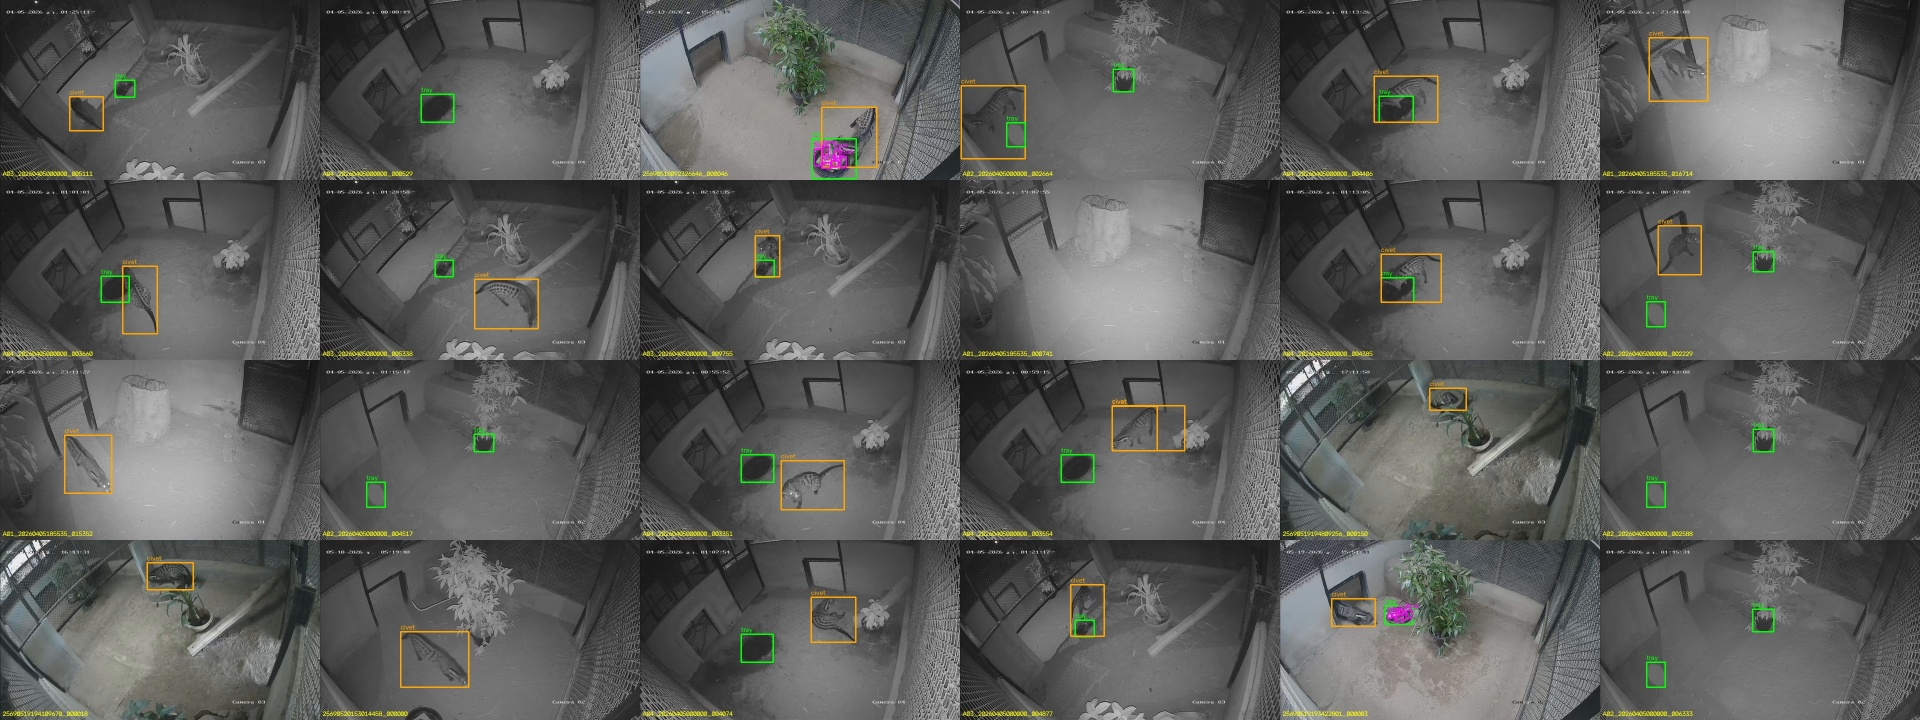

In [6]:
# grid of 24 random previews
import random
random.seed(0)
pics = random.sample(sorted((OUT / "preview").glob("*.jpg")), min(24, len(list((OUT / "preview").glob("*.jpg")))))
tiles = [cv2.resize(cv2.imread(str(p)), (320, 180)) for p in pics]
while len(tiles) % 6: tiles.append(np.zeros((180, 320, 3), np.uint8))
cv2.imwrite(str(OUT / "preview_sample.jpg"), np.vstack([np.hstack(tiles[i:i + 6]) for i in range(0, len(tiles), 6)]))
from IPython.display import Image; Image(str(OUT / "preview_sample.jpg"))

## Fixing bad labels
Put corrected labels in `labels/manual/` or frame names in `labels/reject.txt`.